In [27]:
import numpy as np
import matplotlib.pyplot as plt

In [49]:
def predict_gaussian_map(x, means, variances, priors):
    scores = []
    if np.any(variances <= 0) or np.any(priors <= 0):
        raise ValueError("variance or prior cannot be 0")
    
    if not len(means) == len(variances) == len(priors):
        raise ValueError("All vectors should be of same size")
    
    for mean, variance, prior  in zip(means, variances, priors):
        
        dx = x[0] - mean[0]
        dy = x[1] - mean[1]
        
        sdx = variance[0]
        sdy = variance[1]
        
        standardized_deviations_x = dx/np.sqrt(sdx)
        standardized_deviations_y = dy/np.sqrt(sdy)
        
        d2 = standardized_deviations_x ** 2 + standardized_deviations_y ** 2
        
        score = d2 + np.log(sdx) + np.log(sdy) - 2*np.log(prior)
        
        scores.append(score)
        
    return scores

In [3]:
x = np.array([1., 0.])
means = np.array([[0., 0.], [3., 0.]])
variances = np.array([[1., 1.], [4., 4.]])
priors = np.array([0.5, 0.5])

scores = predict_gaussian_map(x, means, variances, priors)
print(scores)
print(np.argmin(scores), "Winner")

[np.float64(2.386294361119891), np.float64(5.158883083359672)]
0 Winner


In [4]:
x = np.array([1., 0.])
means = np.array([[0., 0.], [3., 0.]])
variances = np.array([[1., 1.], [1., 1.]])
priors = np.array([0.1, 0.9])

scores = predict_gaussian_map(x, means, variances, priors)
print(scores)
print(np.argmin(scores), "Winner")

[np.float64(5.605170185988091), np.float64(4.210721031315653)]
1 Winner


In [5]:
x = np.array([4., 0.])
means = np.array([[0., 0.], [4., 4.]])
variances = np.array([[9., 1.], [9., 1.]])
priors = np.array([0.5, 0.5])

scores = predict_gaussian_map(x, means, variances, priors)
print(scores)
print(np.argmin(scores), "Winner")

[np.float64(5.361296716233888), np.float64(19.58351893845611)]
0 Winner


In [6]:
x = np.array([0., 0.])
means = np.array([[-1., 0.], [1., 0.], [0., 3.]])
variances = np.ones((3, 2))
priors = np.array([0.25, 0.25, 0.5])

scores = predict_gaussian_map(x, means, variances, priors)
print(scores)
print(np.argmin(scores), "Winner")

[np.float64(3.772588722239781), np.float64(3.772588722239781), np.float64(10.38629436111989)]
0 Winner


In [7]:
predict_gaussian_map(
    x=np.array([1., 0.]),
    means=np.array([[0., 0.], [3., 0.]]),
    variances=np.array([[1., 1.], [4., 4.]]),
    priors=np.array([0.0, 1.0])
)

ValueError: variance or prior cannot be 0

In [8]:
x = np.array([0., 0.])
means = np.array([[-1., 0.], [1., 0.], [0., 3.]])
variances = np.ones((3, 2))
priors = np.array([0.25, 0.25])

scores = predict_gaussian_map(x, means, variances, priors)
print(scores)
print(np.argmin(scores), "Winner")

ValueError: All vectors should be of same size

In [9]:
means = np.array([[-2., 0.], [2., 0.]])
variances = np.ones((2, 2))
priors = np.array([0.5, 0.5])

scores = predict_gaussian_map(x, means, variances, priors)
print(scores)
print(np.argmin(scores), "Winner")

[np.float64(5.386294361119891), np.float64(5.386294361119891)]
0 Winner


In [12]:
xs = np.linspace(-6, 6, 121)
ys = np.linspace(-6, 6, 121)
xx, yy = np.meshgrid(xs, ys)

xx.shape, yy.shape

((121, 121), (121, 121))

In [33]:
def calc_map(means, variances, priors):
    winners = np.zeros_like(xx, dtype=int)

    for i in range(xx.shape[0]):
        for j in range(xx.shape[1]):
            x,y = xx[i,j],yy[i,j]
            
            scores = predict_gaussian_map((x,y), means, variances, priors)
            winners[i][j] = (np.argmin(scores))
    return winners

In [32]:
winners[60,50], winners[60,70]

(np.int64(0), np.int64(1))

In [35]:
means = np.array([[-2., 0.], [2., 0.]])
variances = np.ones((2, 2))
priors = np.array([0.8, 0.2])

winners = calc_map(means, variances, priors)

In [37]:
def plot_decision_boundary(winners,means):
    plt.contourf(xx, yy, winners, levels=[-0.5, 0.5, 1.5], colors=["lightblue", "moccasin"])
    plt.scatter(means[:, 0], means[:, 1], c=["blue", "darkorange"], edgecolors="black", s=100)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.gca().set_aspect("equal")
    plt.show()

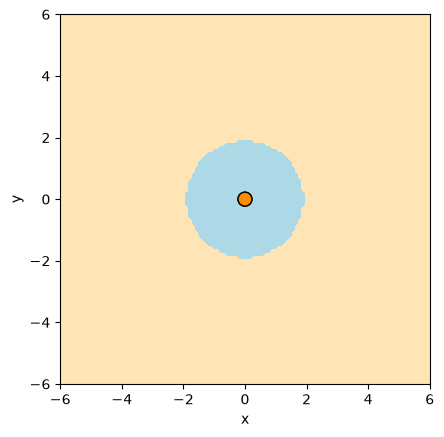

In [38]:
means = np.array([[0., 0.], [0., 0.]])
variances = np.array([[1., 1.], [4., 4.]])
priors = np.array([0.5, 0.5])

winners = calc_map(means, variances, priors)
plot_decision_boundary(winners,means)

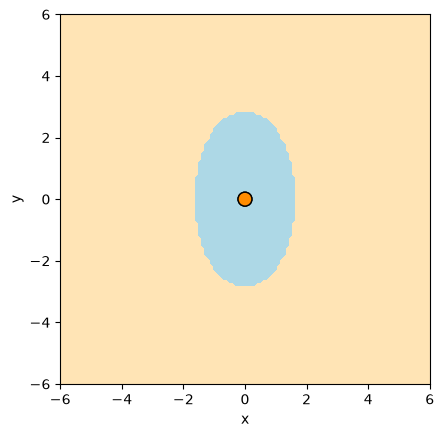

In [ ]:
means = np.array([[0., 0.], [0., 0.]])
variances = np.array([[1., 2.], [4., 4.]])
priors = np.array([0.5, 0.5])

winners = calc_map(means, variances, priors)
plot_decision_boundary(winners,means)

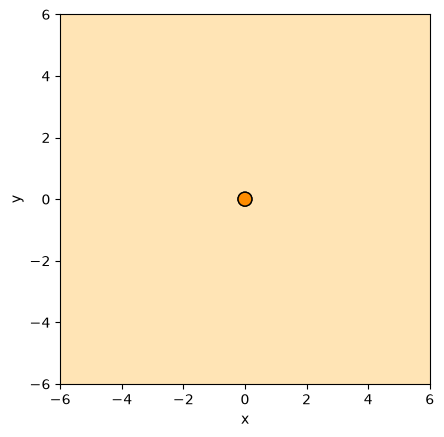

In [40]:
means = np.array([[0., 0.], [0., 0.]])
variances = np.array([[1., 2.], [4., 4.]])
priors = np.array([0.1, 0.9])\

winners = calc_map(means, variances, priors)
plot_decision_boundary(winners,means)

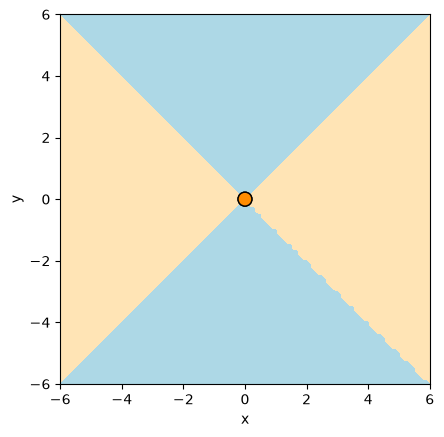

In [41]:
means = np.array([[0., 0.], [0., 0.]])
variances = np.array([[1., 4.], [4., 1.]])
priors = np.array([0.5, 0.5])

winners = calc_map(means, variances, priors)
plot_decision_boundary(winners,means)

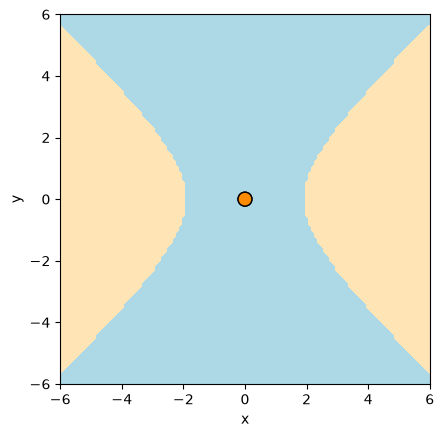

In [42]:
means = np.array([[0., 0.], [0., 0.]])
variances = np.array([[1., 4.], [4., 1.]])
priors = np.array([0.8, 0.2])

winners = calc_map(means, variances, priors)
plot_decision_boundary(winners,means)

In [63]:
def mahalanobis_sq_full(x, mean, cov):
    delta = x - mean
    d2 = delta @ np.linalg.inv(cov) @ delta
    return d2

In [120]:
def predict_gaussian_map_cov(x, means, covariances, priors):
    scores = []
    if np.any(priors <= 0):
        raise ValueError("variance or prior cannot be 0")
    
    if not len(means) == len(priors):
        raise ValueError("All vectors should be of same size")
    
    for mean, cov, prior  in zip(means, covariances, priors):
        
        if not np.allclose(cov, cov.T):
            raise ValueError("Covariance must be symmetric")

        if np.any(np.diag(cov) <= 0):
            raise ValueError("Diagonal variances must be positive")

        if np.linalg.det(cov) <= 0:
            raise ValueError("Covariance must have a positive determinant")
        
        d2 = mahalanobis_sq_full(x, mean, cov)
        
        score = d2 + np.log(np.linalg.det(cov)) - 2*np.log(prior)
        
        scores.append(score)
        
    return scores

In [65]:
x = np.array([1., 2.])
mean = np.array([0., 0.])
cov = np.array([[2/3, 1/3],
                [1/3, 2/3]])

mahalanobis_sq_full(x, mean, cov)

np.float64(6.0)

In [66]:
x = np.array([3., 5.])
mean = np.array([1., 2.])
cov = np.array([[4, 0],
                [0, 1]])

mahalanobis_sq_full(x, mean, cov)

np.float64(10.0)

In [67]:
x = np.array([1., 2.])
mean = np.array([1., 2.])
cov = np.array([[2, 1],
                [1, 2]])

mahalanobis_sq_full(x, mean, cov)

np.float64(0.0)

In [68]:
x = np.array([1., 1.])
means = np.array([[0., 0.], [0., 0.]])
covariances = np.array([
    [[2., 1.], [1., 2.]],
    [[2., 0.], [0., 2.]]
])
priors = np.array([0.5, 0.5])

predict_gaussian_map_cov(x, means, covariances, priors)

[np.float64(3.151573316454667), np.float64(3.7725887222397816)]

In [69]:
means = np.array([[0., 0.], [0., 0.]])
covariances = np.array([
    [[2., 1.], [1., 2.]],
    [[4., 0.], [0., 4.]]
])
priors = np.array([0.5, 0.5])

predict_gaussian_map_cov(x, means, covariances, priors)

[np.float64(3.151573316454667), np.float64(4.6588830833596715)]

In [70]:
def calc_map_full(means, variances, priors):
    winners = np.zeros_like(xx, dtype=int)

    for i in range(xx.shape[0]):
        for j in range(xx.shape[1]):
            x,y = xx[i,j],yy[i,j]
            
            scores = predict_gaussian_map_cov((x,y), means, variances, priors)
            winners[i][j] = (np.argmin(scores))
    return winners

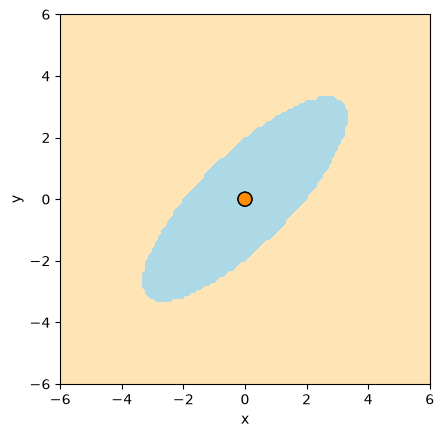

In [71]:
means = np.array([[0., 0.], [0., 0.]])
covariances = np.array([
    [[2., 1.], [1., 2.]],
    [[4., 0.], [0., 4.]]
])
priors = np.array([0.5, 0.5])

winners_full = calc_map_full(means, covariances, priors)
plot_decision_boundary(winners_full, means)

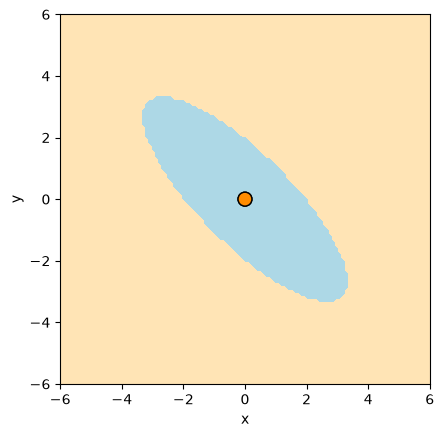

In [72]:
means = np.array([[0., 0.], [0., 0.]])
covariances = np.array([
    [[2., -1.], [-1., 2.]],
    [[4., 0.], [0., 4.]]
])
priors = np.array([0.5, 0.5])

winners_full = calc_map_full(means, covariances, priors)
plot_decision_boundary(winners_full, means)

In [ ]:
matrix = [[2., 1.], [1., 2.]]

x = np.array([0., 0.])
means = np.array([[0., 0.]])
priors = np.array([1.])
covariances = np.array([matrix])

predict_gaussian_map_cov(x, means, covariances, priors)

[np.float64(1.0986122886681096)]

In [75]:
matrix = [[2., -1.], [1., 2.]]

x = np.array([0., 0.])
means = np.array([[0., 0.]])
priors = np.array([1.])
covariances = np.array([matrix])

predict_gaussian_map_cov(x, means, covariances, priors)

ValueError: Covariance must be symmetric

In [76]:
matrix = [[1., 2.], [2., 1.]]

x = np.array([0., 0.])
means = np.array([[0., 0.]])
priors = np.array([1.])
covariances = np.array([matrix])

predict_gaussian_map_cov(x, means, covariances, priors)

ValueError: Covariance must have a positive determinant

In [77]:
matrix = [[1., 1.], [1., 1.]]

x = np.array([0., 0.])
means = np.array([[0., 0.]])
priors = np.array([1.])
covariances = np.array([matrix])

predict_gaussian_map_cov(x, means, covariances, priors)

ValueError: Covariance must have a positive determinant

In [78]:
matrix = [[-1., 0.], [0., -1.]]

x = np.array([0., 0.])
means = np.array([[0., 0.]])
priors = np.array([1.])
covariances = np.array([matrix])

predict_gaussian_map_cov(x, means, covariances, priors)

ValueError: Diagonal variances must be positive

In [85]:
def fit_gaussian(X, epsilon=0.0):

    x_sum, y_sum = 0,0
    N = len(X)
    
    for x in X:
        x_sum += x[0]
        y_sum += x[1]
        
    mean = [x_sum/N, y_sum/N]
    
    D = X - mean
    
    cov = (D.T @ D)/N
    
    cov = cov + epsilon*np.eye(X.shape[1])
    
    return [mean, cov]

In [82]:
X = np.array([[1., 2.], [3., 4.], [5., 3.]])

fit_gaussian(X)

[[np.float64(3.0), np.float64(3.0)],
 array([[2.66666667, 0.66666667],
        [0.66666667, 0.66666667]])]

In [83]:
X = np.array([[0., 4.], [2., 0.], [4., 2.]])

fit_gaussian(X)

[[np.float64(2.0), np.float64(2.0)],
 array([[ 2.66666667, -1.33333333],
        [-1.33333333,  2.66666667]])]

In [86]:
X = np.array([[1., 2.], [1., 2.], [1., 2.]])

fit_gaussian(X, epsilon=0.01)

[[np.float64(1.0), np.float64(2.0)],
 array([[0.01, 0.  ],
        [0.  , 0.01]])]

In [88]:
X = np.array([
    [0., 0.], [2., 0.], [0., 2.],  # class 0
    [4., 4.], [6., 4.], [4., 6.]   # class 1
])
y = np.array([0, 0, 0, 1, 1, 1])

X[y==0]

array([[0., 0.],
       [2., 0.],
       [0., 2.]])

In [112]:
def fit_gaussian_classes(X, y):
    classes = np.unique(y)
    N = len(X)
    priors, means, covs = [], [], []
    for cl in classes:
        mean, cov = fit_gaussian(X[y==cl], epsilon=0.01)
        means.append(mean)
        covs.append(cov)
        priors.append(len(X[y==cl])/N)

    return means, covs, priors

In [132]:
X = np.array([
    [0., 0.], [2., 0.], [0., 2.],  # class 0
    [4., 4.], [6., 4.], [4., 6.]   # class 1
])
y = np.array([0, 0, 0, 1, 1, 1])

means, covs, priors = fit_gaussian_classes(X,y)

for mean, cov, prior in zip(means, covs, priors):
    print(f"""
    Mean : {mean}
    Covariance : {cov}
    Prior : {prior}
    """)
    
x = np.asarray(x, dtype=float)
means = np.asarray(means, dtype=float)
covs = np.asarray(covs, dtype=float)
priors = np.asarray(priors, dtype=float)


    Mean : [np.float64(0.6666666666666666), np.float64(0.6666666666666666)]
    Covariance : [[ 0.89888889 -0.44444444]
 [-0.44444444  0.89888889]]
    Prior : 0.5
    

    Mean : [np.float64(4.666666666666667), np.float64(4.666666666666667)]
    Covariance : [[ 0.89888889 -0.44444444]
 [-0.44444444  0.89888889]]
    Prior : 0.5
    


In [133]:
print("means:", means)
print("covariances:", covs)
print("covariance shape:", np.asarray(covs).shape)
print("priors:", priors)

means: [[0.66666667 0.66666667]
 [4.66666667 4.66666667]]
covariances: [[[ 0.89888889 -0.44444444]
  [-0.44444444  0.89888889]]

 [[ 0.89888889 -0.44444444]
  [-0.44444444  0.89888889]]]
covariance shape: (2, 2, 2)
priors: [0.5 0.5]


In [135]:
x = np.array([0., 0.])
scores = predict_gaussian_map_cov(x, means, covs, priors)
print(np.argmin(scores))

0


In [138]:
# Expected winner: class 1
score = predict_gaussian_map_cov(np.array([5., 5.]), means, covs, priors)

# Expected: equal scores within floating-point tolerance
scores = predict_gaussian_map_cov(
    np.array([8/3, 8/3]), means, covs, priors
)
print(np.argmin(score),np.isclose(scores[0], scores[1]))  # expected True

1 True


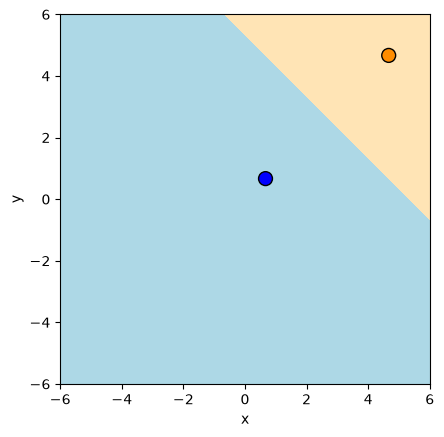

In [141]:
winners_full = calc_map_full(means, covs, priors)
plot_decision_boundary(winners_full, means)

In [142]:
X_test = np.array([
    [1., 0.], [0., 1.], [2., 1.],
    [5., 4.], [4., 5.], [3., 4.]
])
y_test = np.array([0, 0, 0, 1, 1, 1])

In [143]:
for x in X_test:
    scores = predict_gaussian_map_cov(x, means, covs, priors)
    print(np.argmin(scores))

0
0
0
1
1
1
